# CV03 Object Detection

### Lab Description
This laboratory exercise introduces **YOLOv9**, a state-of-the-art one-stage object detection model.  
Unlike traditional detectors, YOLO (“You Only Look Once”) achieves high accuracy and speed by performing detection in a single forward pass, making it suitable for real-time applications.

In this hands-on lab, you will:
- **Train** YOLOv9 on a sample dataset for ~10 epochs.  
- **Evaluate** the trained model on validation/test images.  
- Record and visualize runtime, batch size, and GPU memory usage.  
- Plot training curves to verify the learning process.

#### Recommended Hardware
AMD Ryzen™ AI Halo Processors (e.g., AI Max+ 395, AI Max 390)
#### Software Environment
OS: Ubuntu 24.04.3 LTS \
Install [AUP learning cloud](https://amdresearch.github.io/aup-learning-cloud/installation/quick-start.html?family=ryzen-ai&gpu=max-pro-395). After installing AUP Learning Cloud, you will have a ROCm and PyTorch environment that is compatible with this notebook.

## Goals

- Understand single-stage object detection and the YOLO architecture
- Train YOLOv9 on a sample dataset using the Ultralytics framework
- Evaluate detection results on validation and test images
- Record and visualize training curves and GPU resource usage
- Visualize predicted bounding boxes on test images


In [1]:
import os
import sys

import torch

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("CUDA device:", torch.cuda.get_device_name(0))

Python: 3.12.3
PyTorch: 2.9.1+rocm7.13.0
CUDA available: True
CUDA device: Radeon 8060S Graphics


In [2]:
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/home/jovyan/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


## 2. Download COCO128 & Create Data YAML
We use a **tiny COCO subset** (COCO128) so training finishes quickly.
The first run downloads it (about 7 MB) to `~/data/YOLOv9_data/datasets`, then writes a data YAML that points there.

In [3]:
# Keep datasets, training runs and outputs under ~/data
import yaml
from ultralytics.utils.checks import check_yaml
from ultralytics.utils.downloads import download

DATA_DIR = os.path.expanduser("~/data/YOLOv9_data")
DATASETS_DIR = os.path.join(DATA_DIR, "datasets")
os.makedirs(DATASETS_DIR, exist_ok=True)
os.chdir(DATA_DIR)
print("Working directory:", os.getcwd())

# Start from the COCO128 config that ships with Ultralytics
with open(check_yaml("coco128.yaml")) as f:
    data_cfg = yaml.safe_load(f)

COCO128_DIR = os.path.join(DATASETS_DIR, "coco128")
if not os.path.isdir(COCO128_DIR):
    download(data_cfg["download"], dir=DATASETS_DIR)
print("Dataset directory:", COCO128_DIR)

# Point the data YAML at the local copy
data_cfg["path"] = COCO128_DIR
data_cfg.pop("download", None)
DATA_YAML = os.path.join(DATA_DIR, "coco128.yaml")
with open(DATA_YAML, "w") as f:
    yaml.safe_dump(data_cfg, f, sort_keys=False)
print("Data YAML:", DATA_YAML)

Working directory: /home/jovyan/data/YOLOv9_data
Unzipping /home/jovyan/data/YOLOv9_data/datasets/coco128.zip to /home/jovyan/data/YOLOv9_data/datasets/coco128...: 100% ━━━━━━━━━━━━ 263/263 7.5Kfiles/s 0.0s
Dataset directory: /home/jovyan/data/YOLOv9_data/datasets/coco128
Data YAML: /home/jovyan/data/YOLOv9_data/coco128.yaml


## 3. Training

In [4]:
# Build a YOLOv9c model from pretrained weight
model = YOLO("yolov9c.pt")

In [5]:
model.info()

YOLOv9c summary: 358 layers, 25,590,912 parameters, 0 gradients, 104.0 GFLOPs


(358, 25590912, 0, 104.0144896)

In [6]:
results = model.train(data=DATA_YAML, epochs=10, imgsz=640, batch=4)

New https://pypi.org/project/ultralytics/8.4.219 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.218 🚀 Python-3.12.3 torch-2.9.1+rocm7.13.0 CUDA:0 (Radeon 8060S Graphics, 65536MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/jovyan/data/YOLOv9_data/coco128.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=trai

MIOpen(HIP): Warning [ParseAndLoadDb] File is unreadable: "/usr/local/lib/python3.12/dist-packages/_rocm_sdk_libraries_gfx1151/share/miopen/db/gfx1151_20.HIP.fdb.txt"


AMP: checks passed ✅
train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3958.6±1851.9 MB/s, size: 50.9 KB)
train: Scanning /home/jovyan/data/YOLOv9_data/datasets/coco128/labels/train2017... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 4.3Kit/s 0.0s
train: New cache created: /home/jovyan/data/YOLOv9_data/datasets/coco128/labels/train2017.cache
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5248.5±2529.2 MB/s, size: 52.5 KB)
val: Scanning /home/jovyan/data/YOLOv9_data/datasets/coco128/labels/train2017.cache... 126 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 76.7Mit/s 0.0s
optimizer: 'optimizer=auto' found, ignoring 'lr0=0.01' and determining best 'optimizer' and 'lr0' automatically... 
optimizer: AdamW(lr=0.000119, momentum=0.9) with parameter groups 154 weight(decay=0.0), 161 weight(decay=0.0005), 160 bias(decay=0.0)
Plotting labels to /home/jovyan/data/YOLOv9_data/runs/detect/train/labels.jpg... 
Using 128 train, 128 val images for fraction=1.0 at

       1/10      3.15G     0.9112      1.052      1.099         10        640: 100% ━━━━━━━━━━━━ 32/32 3.0s/it 1:36
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 12.2s/it 3:16
                   all        128        929      0.789      0.708      0.809      0.635

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/10      3.45G     0.9616      1.027       1.12         36        640: 100% ━━━━━━━━━━━━ 32/32 6.4it/s 5.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 15.3it/s 1.0s
                   all        128        929      0.795       0.71      0.796      0.628

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/10      4.16G     0.9629     0.8821      1.121         23        640: 100% ━━━━━━━━━━━━ 32/32 6.5it/s 5.0s
                 Class     Images  Instances      Box(P     

## 4. Evaluation

In [7]:
from ultralytics.utils import ASSETS

# Sample images shipped with Ultralytics
results = model([str(ASSETS / "bus.jpg"), str(ASSETS / "zidane.jpg")])


0: 640x640 4 persons, 1 bus, 1 handbag, 16.8ms
1: 640x640 2 persons, 2 ties, 16.8ms
Speed: 0.8ms preprocess, 16.8ms inference, 0.5ms postprocess per image at shape (1, 3, 640, 640)


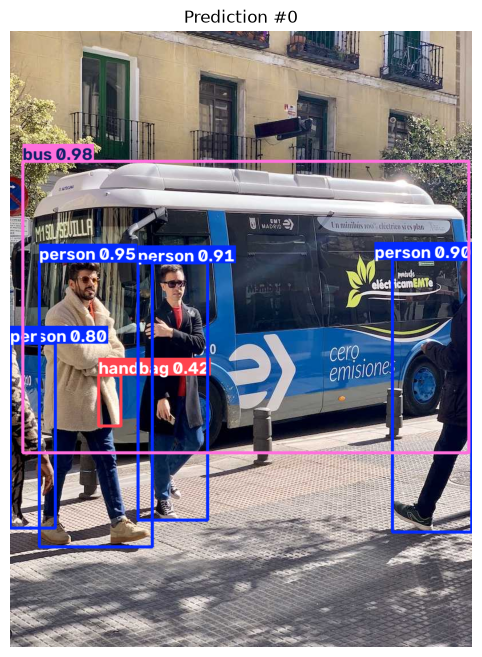

Saved: /home/jovyan/data/YOLOv9_data/results/bus_pred.jpg


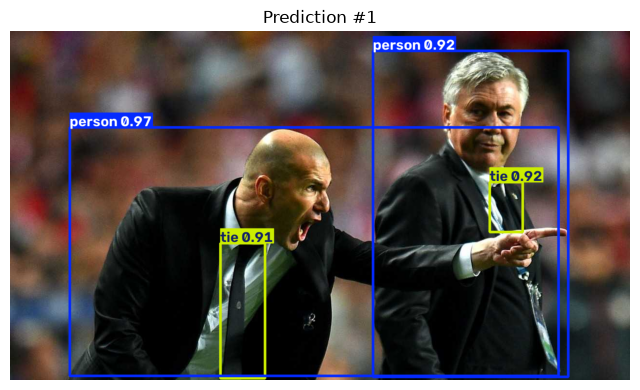

Saved: /home/jovyan/data/YOLOv9_data/results/zidane_pred.jpg


In [8]:
import contextlib
import pathlib

from matplotlib import pyplot as plt
from PIL import Image

OUTPUT_DIR = os.path.join(DATA_DIR, "results")
for i, r in enumerate(results):
    im_bgr = r.plot()
    im_rgb = im_bgr[:, :, ::-1]

    plt.figure(figsize=(8, 8))
    plt.imshow(im_rgb)
    plt.axis("off")
    plt.title(f"Prediction #{i}")
    plt.show()

    os.makedirs(OUTPUT_DIR, exist_ok=True)
    stem = f"pred_{i}"
    with contextlib.suppress(Exception):
        stem = pathlib.Path(r.path).stem
    out_file = os.path.join(OUTPUT_DIR, f"{stem}_pred.jpg")
    Image.fromarray(im_rgb).save(out_file)
    print("Saved:", out_file)

## Conclusions

In this lab, you trained YOLOv9 for real-time object detection. You learned how single-stage detectors perform detection in one forward pass, and evaluated detection results through visualization and training curve analysis.

---

Copyright (C) 2025 Advanced Micro Devices, Inc. All rights reserved. Portions of this file consist of AI-generated content.
SPDX-License-Identifier: MIT